# CUB baseline 分析

这一节：**模型在看哪里**。


## 一、类激活图 CAM

用一组样本的 CAM（类激活图），看训练好的模型对该图做出判断时，注意力在哪。

**CAM 是什么？** 其实就是对特征图（特征通道）做**加权求和**。一张 448x448 的图经过
ResNet50 的 backbone 后得到特征张量 `[1, 2048, 14, 14]`，即 2048 个 14x14 的特征图，
每个特征图会响应（activate）原图的一部分区域[1]。

假设模型对这张图的**预测类别**为 $c$，CAM 就是把这一组 2048 个特征图按照 $W_c$ 加权求和，
$W_c \in \mathbb{R}^{2048}$ 是分类头权重矩阵 $W$ 的第 $c$ 行。

> **两个容易说错的地方**
>
> **1. 是加权求和，不是加权平均。** $W_c$ 不归一，而且可正可负 —— 它表示"第 $j$ 个通道
> 给第 $c$ 类投多少票"，不是"平均意见"。正是因为它是求和，下一步那个 $1/196$ 才能干净地
> 提到最前面。
>
> **2. 用预测类，不是真值类。** 我们问的是"模型凭什么做出这个判断"；用真值类回答的是
> "模型认为哪些区域支持正确类"，那是另一个问题（只有分析错例时才用得上）。

**类 $c$ 的分类得分可以这样算：**

先把 2048 个特征图各自压成一个数（GAP，全局平均池化）：

$$\mathrm{GAP}(F_j) = \frac{1}{196}\sum_{h,w}F_{jhw}$$

再按 $W_c$ 加权求和，加上 bias：

$$\mathrm{logit}_c = \sum_j W_{cj}\,\mathrm{GAP}(F_j) + b_c$$

**把 GAP 的定义代进去**，把常数 $1/196$ 提到最前面：

$$\mathrm{logit}_c - b_c = \frac{1}{196}\sum_j\sum_{h,w}W_{cj}F_{jhw}$$

**交换这两个求和的顺序** —— 这只是同一批数的两种加法顺序（先按通道加，还是先按位置加，
结果一样）：

$$\mathrm{logit}_c - b_c = \frac{1}{196}\sum_{h,w}\Big[\sum_j W_{cj}F_{jhw}\Big]$$

方括号里那部分，对每个空间位置 $(h,w)$ 都算出一个标量，正好凑成一张 14x14 的图。
**给它一个名字：**

$$\boxed{\;\mathrm{CAM}_c[h,w] \;\triangleq\; \sum_j W_{cj}F_{jhw}\;}$$

也就是：**把分类头第 $c$ 行的权重 $W_c$（2048 维）当作系数，对 2048 个特征图逐位置做加权
求和** —— 第 $j$ 个特征图在位置 $(h,w)$ 上的值 $F_{jhw}$，乘上它对第 $c$ 类的投票权重
$W_{cj}$，再把 2048 项加起来。

**再代回上面那个式子**：

$$\mathrm{logit}_c - b_c = \frac{1}{196}\sum_{h,w}\mathrm{CAM}_c[h,w]$$

**也就是说：CAM 这张 14x14 图的平均值（再加 bias），就是第 $c$ 类的分类得分。**
所以这张图上亮的地方，就是"让这个类得分变高的地方" —— 那就是模型在看的地方。

换个说法概括：CAM 只是把 $\mathrm{logit}$ 计算里"对通道求和"这一步，**从 GAP 之后挪到了
GAP 之前**。挪完之后，剩下的那 14x14 就自然带上了空间信息。

### 下面那张图看什么

- **左列**：448x448 的输入裁剪。绿框 = GT bbox（只在**测量**时用，不参与训练），
  白叉 = CAM 峰值所在的格子，叠加的热力图 = CAM。
- **右列**：未经插值的 14x14 CAM 原始数值。

样本按**峰值格占的质量**排序：上面 3 张最集中（模型盯着鸟的某个部位），下面 3 张最弥散
（模型在看整片场景）。

[1] 《解析深度学习（第二版）》


In [1]:
import sys
sys.path.insert(0, '.')

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from torchvision import transforms

from dataset.cub import CUBDataset
from dataset.transforms import build_transform, resolve_data_config
from engine.trainer import read_checkpoint
from model.classifier import build_model
from utils.config import resolve_path

CKPT = 'outputs/04_mixup/a1_448_mix_e100/20261016-214738/last.pth'
DEV = torch.device('cuda')

ckpt = read_checkpoint(CKPT, map_location=DEV)
cfg = ckpt['config']
IMG_SZ = cfg['DATASET']['image_size']

model = build_model(cfg).to(DEV)
model.load_state_dict(ckpt['model'])
model.eval()

dcfg = resolve_data_config(model.backbone)
ROOT = resolve_path(cfg['DATASET']['root'])
RSZ = int(round(IMG_SZ / (dcfg.get('crop_pct') or 1.0)))
GRID = IMG_SZ // 32                      # R50 总下采样 32 -> 14

# 和 eval 完全相同的几何变换，但不转张量，用来画图
tf_vis = transforms.Compose([transforms.Resize(RSZ), transforms.CenterCrop(IMG_SZ)])
ds = CUBDataset(ROOT, 'test', build_transform(dcfg, IMG_SZ, train=False),
                cfg['DATASET']['num_classes'])
W_head = model.head.fc.weight.detach()

img_name = {}
for line in open(ROOT / 'images.txt'):
    i, p = line.split(); img_name[int(i)] = p
gt_box = {}
for line in open(ROOT / 'bounding_boxes.txt'):
    i, x, y, w, h = line.split(); gt_box[int(i)] = np.array([x, y, w, h], float)


def analyse(idx):
    """一张测试图：CAM、GT 框映射到裁剪坐标、框内质量、峰值位置。"""
    s = ds[idx]
    iid, y = int(s['image_id']), int(s['label'])
    x = s['image'].unsqueeze(0).to(DEV)
    with torch.no_grad():
        feat = model.backbone.forward_features(x)              # [1,2048,14,14]
        logits = model.head(model.backbone.forward_head(feat))
    pred = int(logits.argmax(1))
    cam = torch.einsum('j,bjhw->bhw', W_head[pred], feat)[0].relu()

    # 原图 -> 裁剪坐标（Resize(RSZ) 缩放 + CenterCrop 平移）
    with Image.open(ROOT / 'images' / img_name[iid]) as im:
        pil = im.convert('RGB'); W0, H0 = pil.size
    sc = RSZ / min(W0, H0)
    ox, oy = (W0 * sc - IMG_SZ) / 2, (H0 * sc - IMG_SZ) / 2
    bx, by, bw, bh = gt_box[iid]
    box = np.array([bx * sc - ox, by * sc - oy, bw * sc, bh * sc])

    # 框落在哪些格子上（按格心判定）
    yy, xx = np.mgrid[0:GRID, 0:GRID]
    mask = ((xx + .5 >= box[0] / 32) & (xx + .5 <= (box[0] + box[2]) / 32) &
            (yy + .5 >= box[1] / 32) & (yy + .5 <= (box[1] + box[3]) / 32))
    p = (cam / cam.sum()).cpu().numpy()
    return dict(iid=iid, y=y, pred=pred, pil=tf_vis(pil), box=box, cam=p, mask=mask,
                in_box=float(p[mask].sum()), peak=divmod(int(cam.argmax()), GRID))


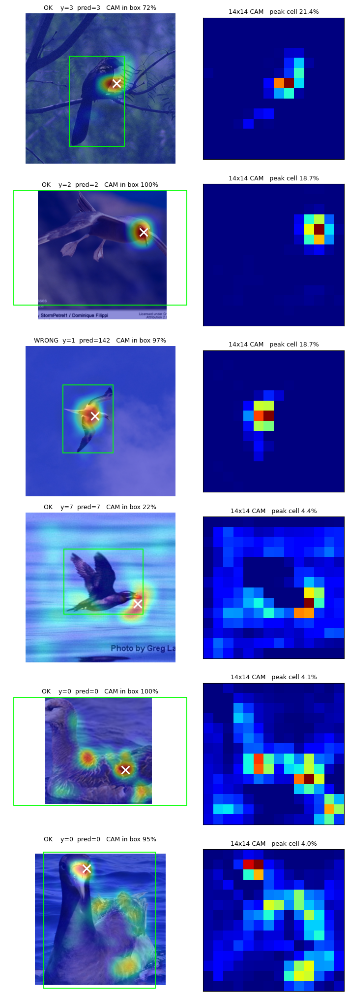

In [2]:
# 扫一遍测试集前 200 张，按「CAM 峰值占的质量」排序
stats = [analyse(i) for i in range(200)]
stats.sort(key=lambda d: -d['cam'].max())
picks = stats[:3] + stats[-3:]              # 最集中的 3 张 + 最弥散的 3 张

fig, axes = plt.subplots(len(picks), 2, figsize=(7.2, 3.4 * len(picks)),
                         gridspec_kw={'width_ratios': [1.35, 1]})
for ax_img, ax_cam, d in zip(axes[:, 0], axes[:, 1], picks):
    ax_img.imshow(d['pil'])
    x, y, w, h = d['box']
    ax_img.add_patch(Rectangle((x, y), w, h, fill=False, ec='lime', lw=1.3))

    cu = F.interpolate(torch.from_numpy(d['cam']).float()[None, None],
                       size=(IMG_SZ, IMG_SZ), mode='bicubic',
                       align_corners=False)[0, 0].numpy()
    ax_img.imshow(cu / cu.max(), cmap='jet', alpha=.45)   # CAM 叠加

    pr, pc = d['peak']                                     # 峰值格子
    ax_img.plot((pc + .5) * 32, (pr + .5) * 32, 'x', color='w', ms=11, mew=2.2)
    mark = 'OK  ' if d['pred'] == d['y'] else 'WRONG'
    ax_img.set_title(f"{mark}  y={d['y']}  pred={d['pred']}   "
                     f"CAM in box {d['in_box'] * 100:.0f}%", fontsize=9)
    ax_img.axis('off')

    ax_cam.imshow(d['cam'], cmap='jet')
    ax_cam.set_title(f"14x14 CAM   peak cell {d['cam'].max() * 100:.1f}%", fontsize=9)
    ax_cam.set_xticks([]); ax_cam.set_yticks([])

plt.tight_layout()
plt.show()


## 三、注意力模块：32 张图到底在看不同地方吗？

`model/attention.py` 的设计意图是：32 个 1×1 卷积核各自学一组通道组合，希望它们分化成
32 个不同的部位探测器（有的看喙、有的看翅膀纹理……）。

但"设计了能分化"不等于"训练出来会分化"。这一节直接测。

用 `attn_weight=1.0` 的那次训练（`a1_448_attn_s10w10`）—— **辅助损失已经给到最大值**。
如果连它都没分化，那"权重太小所以没学好"这个解释就不成立。

测五件事：

| 指标 | 在问什么 | 分化成功的样子 |
|---|---|---|
| 熵 / ln(196) | 单张图有多集中 | 明显小于 1 |
| 图间 Pearson 相关 | 32 张图彼此像不像 | 接近 0 |
| 质心散布 | 32 个部位落在不同位置吗 | 几个格子以上 |
| cos(部位特征, GAP) | 部位特征是不是就是全局平均 | 明显小于 1 |
| 部位预测 = 主头预测 | 32 个部位有没有独立意见 | 明显小于 1 |

In [3]:
# 换成带注意力模块的那次训练（辅助权重 1.0）
ATTN_CKPT = 'outputs/06_attention/a1_448_attn_s10w10/20261017-145442/last.pth'

ck_a = read_checkpoint(ATTN_CKPT, map_location='cpu')
cfg_a = ck_a['config']

model_a = build_model(cfg_a).to(DEV)
model_a.load_state_dict(ck_a['model'])
model_a.eval()

dcfg_a = resolve_data_config(model_a.backbone)
ds_a = CUBDataset(ROOT, 'test', build_transform(dcfg_a, IMG_SZ, train=False),
                  cfg_a['DATASET']['num_classes'])

print(f"attn_weight={cfg_a['TRAIN']['attn_weight']}  "
      f"num_parts={cfg_a['MODEL']['num_parts']}  epoch={ck_a['epoch']}")

attn_weight=1.0  num_parts=32  epoch=49


In [4]:
N = 64
x_a = torch.stack([ds_a[i]['image'] for i in range(N)]).to(DEV)
y_a = torch.tensor([ds_a[i]['label'] for i in range(N)], device=DEV)

attn_conv = model_a.attn_aux.attn
with torch.no_grad():
    feat_a = model_a.backbone.forward_features(x_a)          # [B,2048,14,14]
    B, C, h, w = feat_a.shape
    L = h * w
    A = attn_conv(feat_a).sigmoid()
    A = A / A.sum(dim=(2, 3), keepdim=True)                  # [B,32,14,14]
    Af = A.reshape(B, cfg_a['MODEL']['num_parts'], L)

    gap_a = model_a.backbone.forward_head(feat_a)            # [B,2048]
    f_a = torch.einsum('bkhw,bchw->bkc', A, feat_a)          # [B,K,2048]
    logits_a = model_a.head(gap_a)
    logits_parts = model_a.attn_aux.part_head(f_a)           # [B,K,200]

K = Af.shape[1]

# 1. 单张图的集中度
ent = -(Af.clamp(min=1e-12).log() * Af).sum(-1)
print(f"[熵]        mean={ent.mean():.4f}  min={ent.min():.4f}   "
      f"均匀 ln{L}={np.log(L):.4f}  →  {ent.mean()/np.log(L):.3f} × 均匀")

# 2. 32 张图彼此有多像
# std 必须用 unbiased=False（除以 L），才能和下面的 /L 配成严格的 Pearson；
# 默认的 unbiased=True 除以 L-1，会把结果压低 L-1/L ≈ 0.5%
Z = (Af - Af.mean(-1, keepdim=True)) / Af.std(-1, keepdim=True, unbiased=False).clamp(min=1e-8)
R = torch.bmm(Z, Z.transpose(1, 2)) / L
eye = torch.eye(K, dtype=torch.bool, device=R.device).unsqueeze(0)
offR = R.masked_fill(eye, 0)
print(f"[图间相关]  Pearson mean={offR.mean():.4f}  max={offR.max():.4f}")

# 3. 质心散布
yy, xx = torch.meshgrid(torch.arange(h, device=DEV, dtype=torch.float32),
                        torch.arange(w, device=DEV, dtype=torch.float32), indexing='ij')
cx = (A * xx).sum((2, 3)).detach(); cy = (A * yy).sum((2, 3)).detach()
print(f"[质心散布]  32 个部位的 std: x={cx.std(1).mean():.3f} 格  "
      f"y={cy.std(1).mean():.3f} 格   (完全均匀时应为 {np.sqrt((L-1)/12):.2f} 格)")

# 4. 部位特征 vs 全局平均特征
fn = f_a / f_a.norm(dim=-1, keepdim=True).clamp(min=1e-8)
gn = gap_a / gap_a.norm(dim=-1, keepdim=True).clamp(min=1e-8)
cos_gap = (fn * gn.unsqueeze(1)).sum(-1)
print(f"[特征相似]  cos(部位特征, GAP)  mean={cos_gap.mean():.4f}  min={cos_gap.min():.4f}")

# 5. 32 个部位的意见是否独立
pred_parts = logits_parts.argmax(2)
pred_main = logits_a.argmax(1)
print(f"[预测一致]  部位预测 == 主头预测  {(pred_parts == pred_main.unsqueeze(1)).float().mean():.4f}")
print(f"[准确率]    部位 {(pred_parts == y_a.unsqueeze(1)).float().mean():.4f}   "
      f"主头 {(pred_main == y_a).float().mean():.4f}")

[熵]        mean=5.1254  min=4.9760   均匀 ln196=5.2781  →  0.971 × 均匀
[图间相关]  Pearson mean=0.9208  max=0.9911
[质心散布]  32 个部位的 std: x=0.080 格  y=0.153 格   (完全均匀时应为 4.03 格)
[特征相似]  cos(部位特征, GAP)  mean=0.8858  min=0.7948
[预测一致]  部位预测 == 主头预测  0.9688
[准确率]    部位 0.8750   主头 0.8750


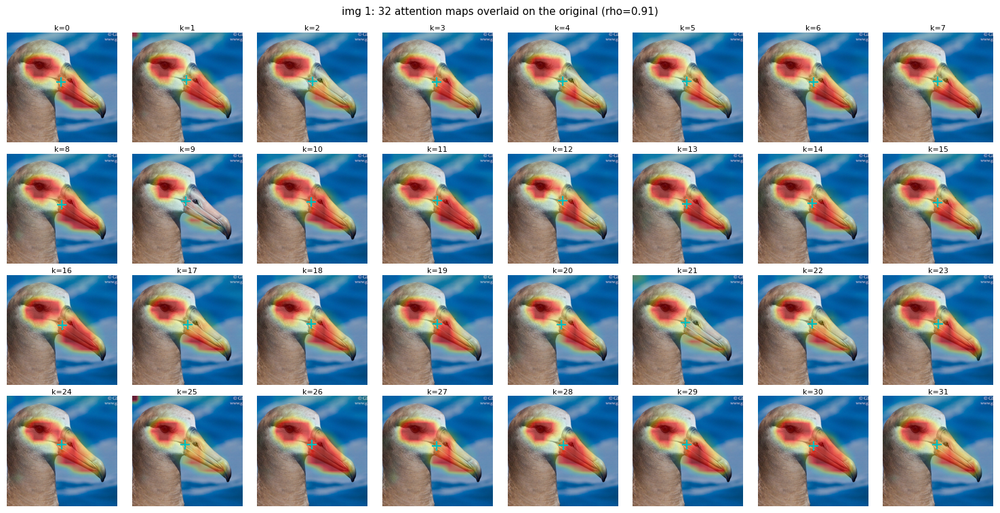

img 1  mean pairwise Pearson=0.911


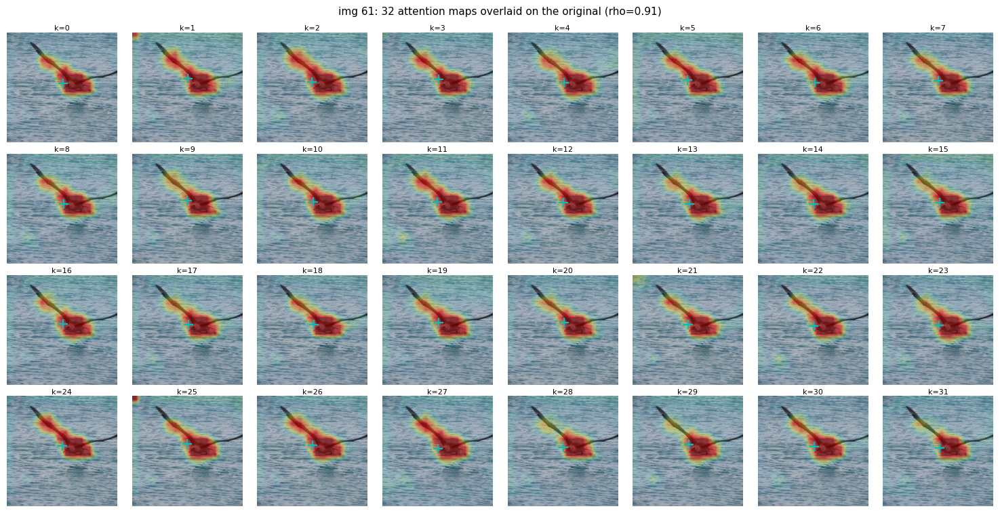

img 61  mean pairwise Pearson=0.915


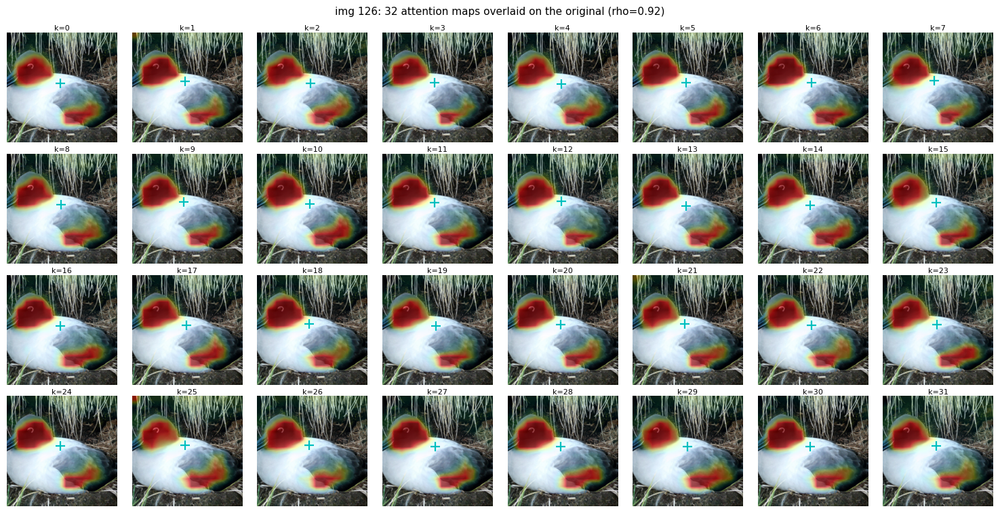

img 126  mean pairwise Pearson=0.922


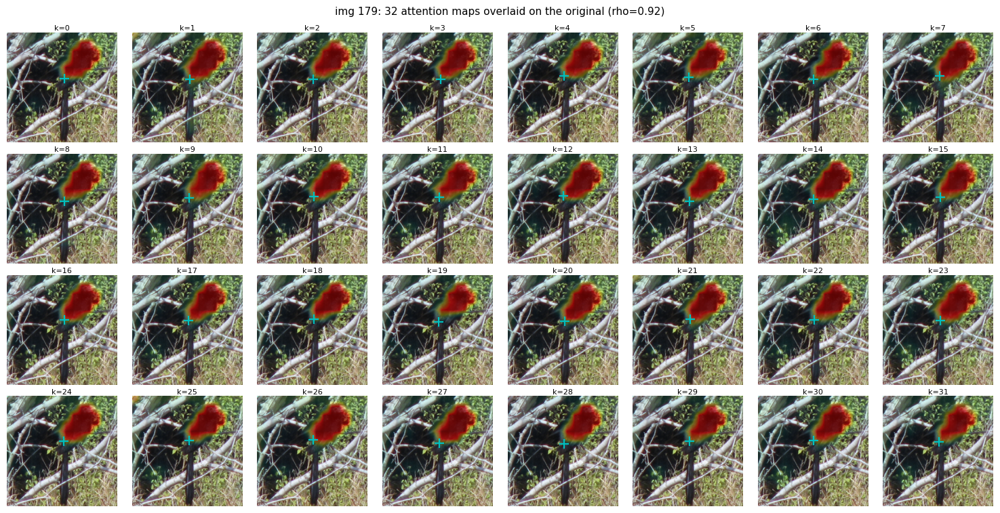

img 179  mean pairwise Pearson=0.921


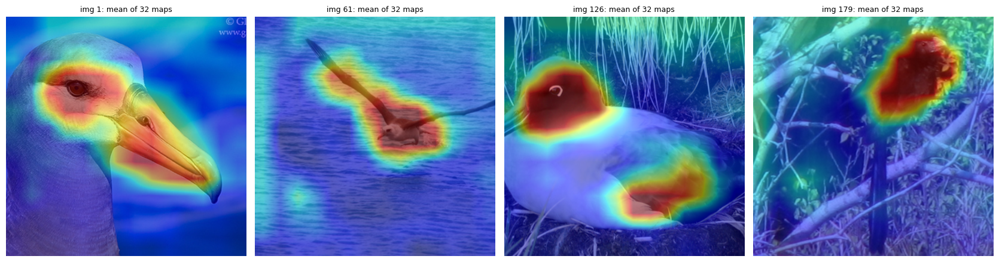

In [5]:
# 多张测试图（不同类别），把每张图的 32 个注意力图分别叠回原图
PICKS, seen = [], set()
for i in range(len(ds_a)):
    y_i = ds_a[i]['label']
    if y_i in seen:
        continue
    seen.add(y_i); PICKS.append(i)
    if len(PICKS) == 4:
        break

x_m = torch.stack([ds_a[i]['image'] for i in PICKS]).to(DEV)
with torch.no_grad():
    feat_m = model_a.backbone.forward_features(x_m)
    A_m = model_a.attn_aux.attn(feat_m).sigmoid()
    A_m = A_m / A_m.sum(dim=(2, 3), keepdim=True)              # [nS, K, 14, 14]
    Af_m = A_m.reshape(len(PICKS), K, L)
    Z_m = (Af_m - Af_m.mean(-1, keepdim=True)) / Af_m.std(-1, keepdim=True, unbiased=False).clamp(min=1e-8)
    R_m = torch.bmm(Z_m, Z_m.transpose(1, 2)) / L
    peer = R_m.masked_fill(eye, 0).mean((1, 2))                # 每张图内 32 张图的相关度

nS = len(PICKS)
yy_np, xx_np = np.mgrid[0:GRID, 0:GRID]


def upscale(a):
    """14x14 -> IMG_SZ，并归一化到 [0,1]（用于透明度）。"""
    t = torch.from_numpy(a)[None, None].float()
    u = F.interpolate(t, size=(IMG_SZ, IMG_SZ), mode='bilinear', align_corners=False)[0, 0].numpy()
    return (u - u.min()) / (u.max() - u.min() + 1e-8)


for r in range(nS):
    iid = ds_a[PICKS[r]]['image_id']
    with Image.open(ROOT / 'images' / img_name[iid]) as im:
        pil_r = tf_vis(im.convert('RGB'))

    fig, axes = plt.subplots(4, 8, figsize=(15, 7.6))
    for k, ax in enumerate(axes.ravel()):
        a = A_m[r, k].cpu().numpy()
        ax.imshow(pil_r)
        # 低响应处透明，只让高响应区染上颜色 —— 否则整张图会被糊上一层蓝
        ax.imshow(upscale(a), cmap='jet', alpha=0.7 * upscale(a) ** 2)
        ax.plot((a * xx_np).sum() * 32 + 16, (a * yy_np).sum() * 32 + 16,
                'c+', ms=10, mew=1.6)
        ax.set_title(f'k={k}', fontsize=8, pad=2)
        ax.axis('off')
    fig.suptitle(f'img {iid}: 32 attention maps overlaid on the original (rho={peer[r]:.2f})',
                 fontsize=11)
    plt.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.01,
                        wspace=0.04, hspace=0.10)
    plt.show()
    print(f'img {iid}  mean pairwise Pearson={peer[r]:.3f}')

# 对照：32 张图的平均叠在原图上
fig, axes = plt.subplots(1, nS, figsize=(4.2 * nS, 4.4))
for r, ax in enumerate(np.atleast_1d(axes)):
    iid = ds_a[PICKS[r]]['image_id']
    with Image.open(ROOT / 'images' / img_name[iid]) as im:
        pil_r = tf_vis(im.convert('RGB'))
    ax.imshow(pil_r)
    ax.imshow(upscale(A_m[r].mean(0).cpu().numpy()), cmap='jet', alpha=0.5)
    ax.set_title(f'img {iid}: mean of 32 maps', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

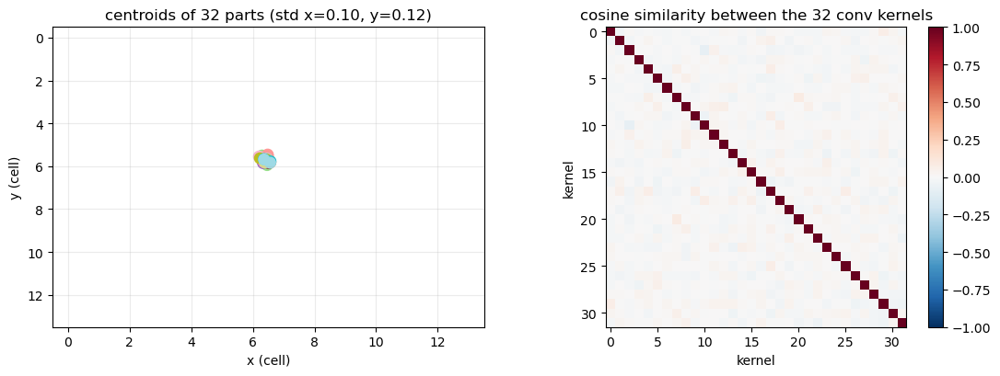

核间余弦: mean|.|=0.0175  max=0.0825  min=-0.0858


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# 左：32 个部位的质心
ax = axes[0]
ax.scatter(cx[0].cpu(), cy[0].cpu(), s=70, c=np.arange(K), cmap='tab20')
ax.set_xlim(-0.5, GRID - 0.5); ax.set_ylim(GRID - 0.5, -0.5)
ax.set_xlabel('x (cell)'); ax.set_ylabel('y (cell)')
ax.set_title(f'centroids of 32 parts (std x={cx[0].std():.2f}, y={cy[0].std():.2f})')
ax.grid(alpha=.25)

# 右：32 个卷积核两两余弦相似度
ax = axes[1]
Wk = attn_conv.weight.squeeze(-1).squeeze(-1)
Wn = (Wk / Wk.norm(dim=1, keepdim=True)).detach()
S = (Wn @ Wn.T).cpu().numpy()
im = ax.imshow(S, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_title('cosine similarity between the 32 conv kernels')
ax.set_xlabel('kernel'); ax.set_ylabel('kernel')
plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

off = S[~np.eye(K, dtype=bool)]
print(f"核间余弦: mean|.|={np.abs(off).mean():.4f}  max={off.max():.4f}  min={off.min():.4f}")

In [7]:
# 决定性对照：同样的结构、同样的特征，只把 32 个核换成「随机初始化」
torch.manual_seed(0)
rand_conv = torch.nn.Conv2d(C, K, kernel_size=1).to(DEV)


def map_stats(conv, tag):
    with torch.no_grad():
        a = conv(feat_a).sigmoid()
        a = a / a.sum(dim=(2, 3), keepdim=True)
        af = a.reshape(B, K, L)
        z = (af - af.mean(-1, keepdim=True)) / af.std(-1, keepdim=True, unbiased=False).clamp(min=1e-8)
        r = torch.bmm(z, z.transpose(1, 2)) / L
        off = r.masked_fill(torch.eye(K, dtype=torch.bool, device=r.device).unsqueeze(0), 0)
        e = -(af.clamp(min=1e-12).log() * af).sum(-1)
    print(f"{tag:12s}  图间 Pearson={off.mean():.4f}   熵/lnL={e.mean()/np.log(L):.4f}")


map_stats(attn_conv, '训练后')
map_stats(rand_conv, '随机初始化')

训练后           图间 Pearson=0.9208   熵/lnL=0.9711
随机初始化         图间 Pearson=-0.0096   熵/lnL=0.9936


## 四、通道和 vs 32 个部位

把 `[nS, 2048, 14, 14]` 沿通道**直接相加**（不加权），得到一张 `[nS, 14, 14]` 的图。
它等于 GAP 特征在空间上的展开——每个格子是 2048 个通道在该位置的总激活。

拿它和 32 个部位的注意力图比：如果两者几乎一样，说明 32 个核学到的就是「整体激活在哪」。

通道和图 vs 32 张注意力图 (Pearson):
  img 1: mean=0.784  min=0.742  max=0.811
  img 61: mean=0.796  min=0.740  max=0.847
  img 126: mean=0.804  min=0.748  max=0.845
  img 179: mean=0.791  min=0.752  max=0.829

通道和图 vs 32 张图的平均: 0.807, 0.817, 0.822, 0.809


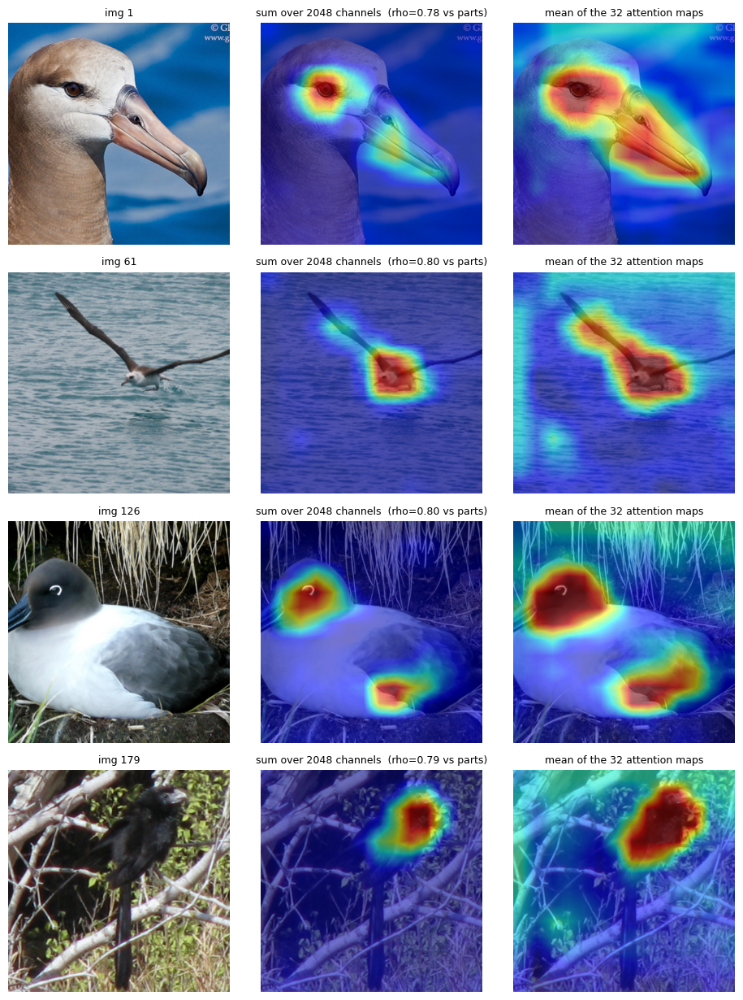

In [8]:
# 通道和（不加权）：[nS,2048,14,14] -> 沿通道求和 -> [nS,14,14]
G_m = feat_m.sum(dim=1)
Gn = G_m.reshape(nS, L)

# 每张注意力图与通道和图的空间相关（沿用上面的 z-score）
Zg = (Gn - Gn.mean(-1, keepdim=True)) / Gn.std(-1, keepdim=True, unbiased=False)
corr_ga = (Z_m * Zg.unsqueeze(1)).mean(-1)                 # [nS, K]

print('通道和图 vs 32 张注意力图 (Pearson):')
for r in range(nS):
    c = corr_ga[r]
    print(f'  img {ds_a[PICKS[r]]["image_id"]}: mean={c.mean():.3f}  '
          f'min={c.min():.3f}  max={c.max():.3f}')

# 通道和图 vs 32 张图的平均
Zmean = (Af_m.mean(1) - Af_m.mean(1).mean(-1, keepdim=True)) / \
        Af_m.mean(1).std(-1, keepdim=True, unbiased=False)
print('\n通道和图 vs 32 张图的平均:',
      ', '.join(f'{(Zg[r] * Zmean[r]).mean():.3f}' for r in range(nS)))

fig, axes = plt.subplots(nS, 3, figsize=(9.6, 3.1 * nS))
for r in range(nS):
    iid = ds_a[PICKS[r]]['image_id']
    with Image.open(ROOT / 'images' / img_name[iid]) as im:
        pil_r = tf_vis(im.convert('RGB'))
    g_up = upscale(G_m[r].cpu().numpy())
    a_up = upscale(A_m[r].mean(0).cpu().numpy())

    axes[r, 0].imshow(pil_r)
    axes[r, 0].set_title(f'img {iid}', fontsize=9)
    axes[r, 1].imshow(pil_r)
    axes[r, 1].imshow(g_up, cmap='jet', alpha=0.55)
    axes[r, 1].set_title(f'sum over 2048 channels  (rho={corr_ga[r].mean():.2f} vs parts)',
                         fontsize=9)
    axes[r, 2].imshow(pil_r)
    axes[r, 2].imshow(a_up, cmap='jet', alpha=0.55)
    axes[r, 2].set_title('mean of the 32 attention maps', fontsize=9)
    for ax in axes[r]:
        ax.axis('off')
plt.tight_layout()
plt.show()

## 五、peak_mask 长什么样

训练时擦除/裁剪用的掩码来自 `peak_mask(cam, alpha)`：CAM 高于 `alpha × 自身最大值` 的格子记为 1。
`alpha` 越小，阈值越低，擦掉的格子越多。

下面用**真值类**算 CAM（和训练时一致），看不同 alpha 实际选出多大一片区域。

mask 覆盖率（擦掉的格子比例）:
  alpha=0.2:   7.8%   平均每张 15.2 格
  alpha=0.3:   5.7%   平均每张 11.2 格
  alpha=0.6:   2.7%   平均每张 5.2 格


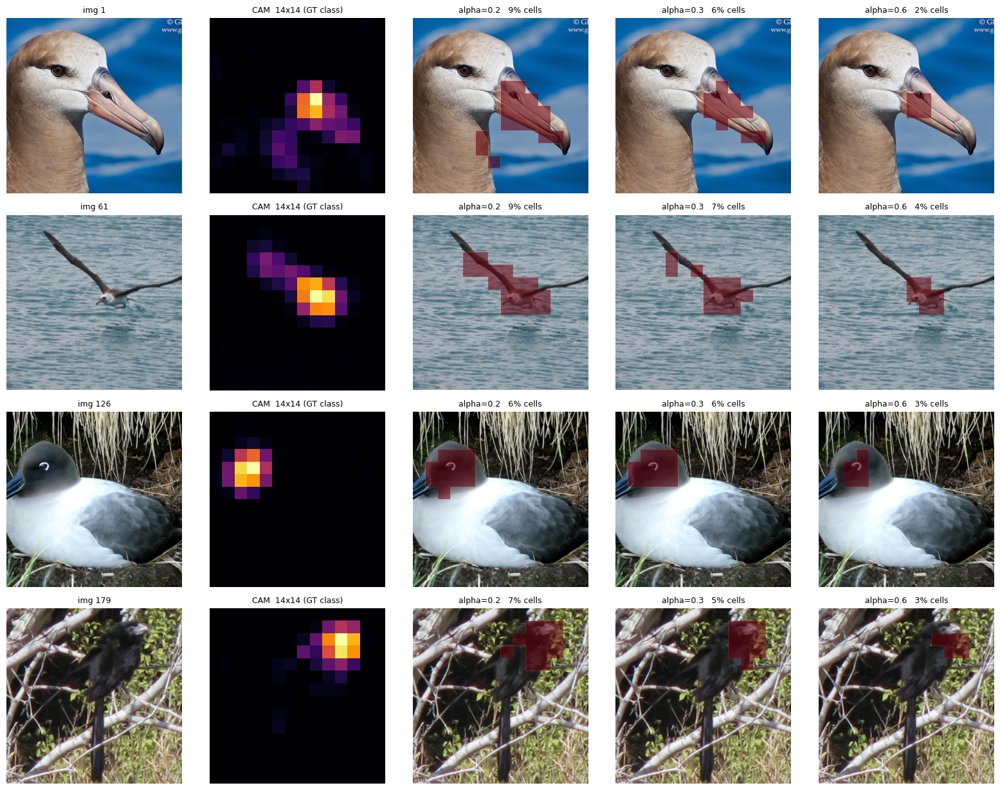

In [9]:
from model.cam_aug import cam_map, peak_mask

ALPHAS = [0.2, 0.3, 0.6]
PICKS_C, seen_c = [], set()
for i in range(len(ds)):
    y_i = ds[i]['label']
    if y_i in seen_c:
        continue
    seen_c.add(y_i); PICKS_C.append(i)
    if len(PICKS_C) == 4:
        break

xc = torch.stack([ds[i]['image'] for i in PICKS_C]).to(DEV)
yc = torch.tensor([ds[i]['label'] for i in PICKS_C], device=DEV)
with torch.no_grad():
    feat_c = model.backbone.forward_features(xc)
    # 真值类 -> CAM（训练时 CamAux 走的是这条；分析错例时才用预测类）
    cam_c = cam_map(feat_c, model.head.fc.weight.detach(), yc)

print('mask 覆盖率（擦掉的格子比例）:')
for a in ALPHAS:
    mk = peak_mask(cam_c, a)
    print(f'  alpha={a}: {mk.mean()*100:5.1f}%   '
          f'平均每张 {mk.sum((1,2,3)).mean():.1f} 格')

fig, axes = plt.subplots(4, 2 + len(ALPHAS), figsize=(3.2 * (2 + len(ALPHAS)), 12.4))
for r in range(4):
    iid = ds[PICKS_C[r]]['image_id']
    with Image.open(ROOT / 'images' / img_name[iid]) as im:
        pil_r = tf_vis(im.convert('RGB'))

    axes[r, 0].imshow(pil_r)
    axes[r, 0].set_title(f'img {iid}', fontsize=9)

    axes[r, 1].imshow(cam_c[r].cpu().numpy(), cmap='inferno', interpolation='nearest')
    axes[r, 1].set_title('CAM  14x14 (GT class)', fontsize=9)

    for j, a in enumerate(ALPHAS):
        mask = peak_mask(cam_c, a)[r, 0].cpu().numpy()
        mup = F.interpolate(torch.from_numpy(mask)[None, None].float(),
                            size=(IMG_SZ, IMG_SZ), mode='nearest')[0, 0].numpy()
        ax = axes[r, 2 + j]
        ax.imshow(pil_r)
        ax.imshow(mup, cmap='Reds', alpha=0.55 * mup)     # 0 处透明
        ax.set_title(f'alpha={a}   {mask.mean()*100:.0f}% cells', fontsize=9)

    for ax in axes[r]:
        ax.axis('off')
plt.tight_layout()
plt.show()

## 六、mask_to_box 的框有多大

`mask_to_box` 取掩码的外接矩形（归一化 `x0,y0,x1,y1`），`crop_and_resize` 再把它按 `margin` 放大后裁原图。

下面在原图上同时画两个框：**绿线 = 掩码外接矩形本身**，**红线 = margin=1.5 之后实际裁剪的范围**。

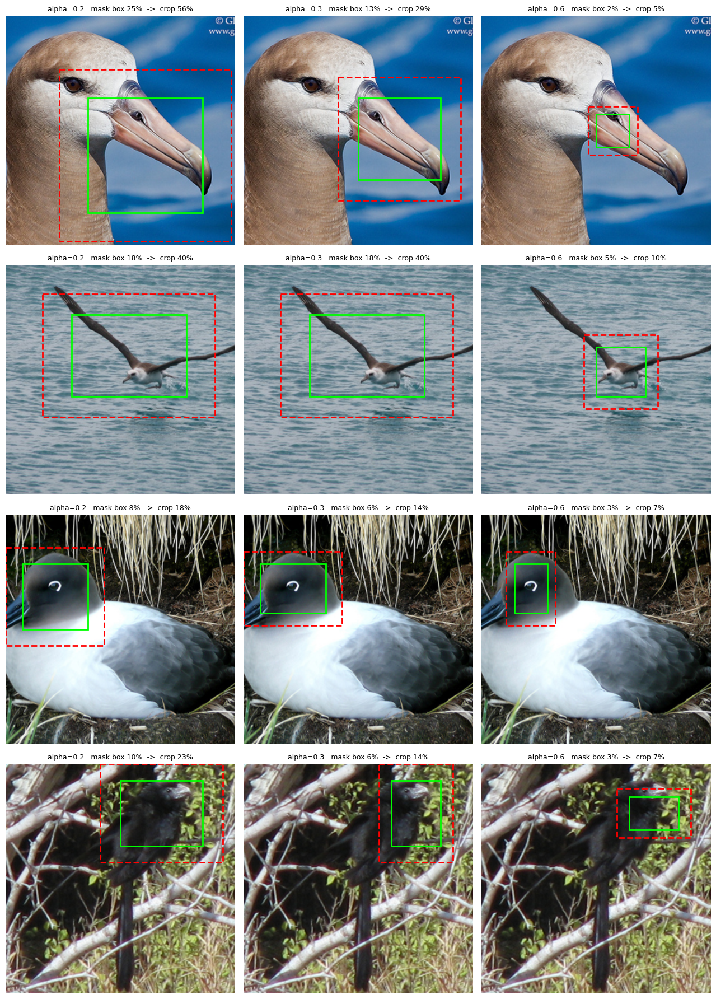

 alpha     mask框面积  margin1.5后
   0.2          15.3%      34.4%
   0.3          10.7%      24.1%
   0.6           3.2%       7.2%


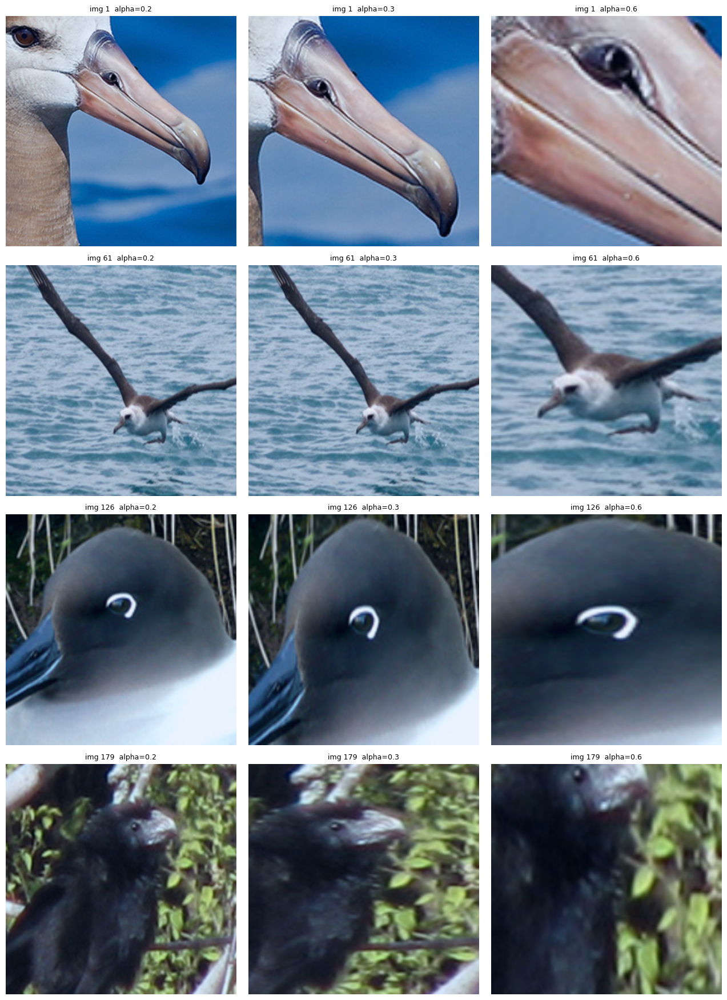

In [10]:
from model.cam_aug import mask_to_box, crop_and_resize

ALPHAS_B = [0.2, 0.3, 0.6]
MARGIN = 1.5

boxes = {}
fig, axes = plt.subplots(4, len(ALPHAS_B), figsize=(4.3 * len(ALPHAS_B), 4.5 * 4))
for r in range(4):
    iid = ds[PICKS_C[r]]['image_id']
    with Image.open(ROOT / 'images' / img_name[iid]) as im:
        pil_r = tf_vis(im.convert('RGB'))

    for j, a in enumerate(ALPHAS_B):
        mask = peak_mask(cam_c, a)[r:r + 1]
        box = mask_to_box(mask)                      # [1,4] 归一化 xyxy
        boxes[(r, a)] = box
        x0, y0, x1, y1 = (box[0].cpu().numpy() * IMG_SZ)

        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        hw, hh = (x1 - x0) * MARGIN / 2, (y1 - y0) * MARGIN / 2
        # crop_and_resize 里会 clamp 到图像边界，这里同样处理
        px0, py0 = max(cx - hw, 0), max(cy - hh, 0)
        px1, py1 = min(cx + hw, IMG_SZ), min(cy + hh, IMG_SZ)
        a_box = (x1 - x0) * (y1 - y0) / IMG_SZ ** 2
        a_crop = (px1 - px0) * (py1 - py0) / IMG_SZ ** 2

        ax = axes[r, j]
        ax.imshow(pil_r)
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0,
                               fill=False, ec='lime', lw=2))
        ax.add_patch(Rectangle((px0, py0), px1 - px0, py1 - py0,
                               fill=False, ec='red', lw=2, ls='--'))
        ax.set_title(f'alpha={a}   mask box {a_box*100:.0f}%  ->  '
                     f'crop {a_crop*100:.0f}%', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

print(f'{"alpha":>6} {"mask框面积":>11} {"margin1.5后":>11}')
for a in ALPHAS_B:
    print(f'{a:6.1f} {"":>3}', end='')
    ab = np.mean([((boxes[(r, a)][0, 2] - boxes[(r, a)][0, 0]) *
                   (boxes[(r, a)][0, 3] - boxes[(r, a)][0, 1])).item() for r in range(4)])
    print(f' {ab*100:9.1f}% {(min(ab*MARGIN**2,1))*100:9.1f}%')

# 实际裁出来的 patch 长什么样
fig, axes = plt.subplots(4, len(ALPHAS_B), figsize=(4.3 * len(ALPHAS_B), 4.4 * 4))
for r in range(4):
    for j, a in enumerate(ALPHAS_B):
        patch = crop_and_resize(xc[r:r + 1], boxes[(r, a)], IMG_SZ, MARGIN)
        img = patch[0].cpu().permute(1, 2, 0).numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)
        axes[r, j].imshow(img)
        axes[r, j].set_title(f'img {ds[PICKS_C[r]]["image_id"]}  alpha={a}', fontsize=9)
        axes[r, j].axis('off')
plt.tight_layout()
plt.show()

## 七、CutMix 到底把图破坏成什么样

`cutmix=1.0` 时混合比例 `lam ~ Beta(1,1)`，贴入面积 = `1 - lam`，**中位数就是 50%**。

下面用真实的 collate 逻辑造几组：左边是原图 A，中间是从 B 剪来的块落点（红框），
右边是混合结果。标题里的 `area` 是实际贴入面积——按 CutMix 的规则，标签就是
`(1-area)·A + area·B`。

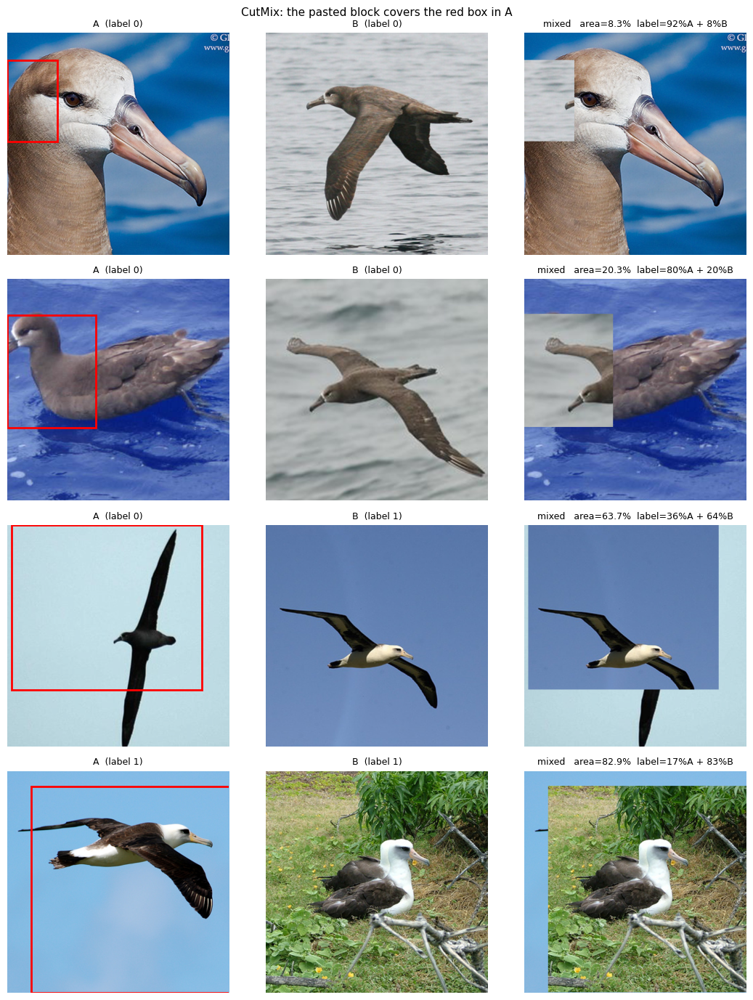

贴入面积 中位数=50.1%  >50%: 50%  >70%: 30%  >90%: 10%


In [11]:
import numpy as np
import torch

def rand_bbox(H, W, lam):
    cut_rat = (1.0 - lam) ** 0.5
    cut_h, cut_w = int(H * cut_rat), int(W * cut_rat)
    cy = int(torch.randint(H, (1,)))
    cx = int(torch.randint(W, (1,)))
    y1, y2 = max(cy - cut_h // 2, 0), min(cy + cut_h // 2, H)
    x1, x2 = max(cx - cut_w // 2, 0), min(cx + cut_w // 2, W)
    return y1, y2, x1, x2

def denorm(t):
    a = t.permute(1, 2, 0).cpu().numpy()
    return np.clip(a * np.array(dcfg['std']) + np.array(dcfg['mean']), 0, 1)

torch.manual_seed(0)
S = IMG_SZ
fig, axes = plt.subplots(4, 3, figsize=(11, 14))
for r in range(4):
    ia, ib = r * 13, r * 13 + 7
    a, b = ds[ia]['image'], ds[ib]['image']
    lam = float(torch.distributions.Beta(1.0, 1.0).sample())
    y1, y2, x1, x2 = rand_bbox(S, S, lam)
    mixed = a.clone()
    mixed[:, y1:y2, x1:x2] = b[:, y1:y2, x1:x2]
    area = (y2 - y1) * (x2 - x1) / (S * S)

    axes[r, 0].imshow(denorm(a))
    axes[r, 0].set_title(f'A  (label {ds[ia]["label"]})', fontsize=9)
    axes[r, 0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                   fill=False, ec='red', lw=2))

    axes[r, 1].imshow(denorm(b))
    axes[r, 1].set_title(f'B  (label {ds[ib]["label"]})', fontsize=9)

    axes[r, 2].imshow(denorm(mixed))
    axes[r, 2].set_title(f'mixed   area={area*100:.1f}%  '
                         f'label={(1-area)*100:.0f}%A + {area*100:.0f}%B',
                         fontsize=9)
    for ax in axes[r]:
        ax.axis('off')
plt.suptitle('CutMix: the pasted block covers the red box in A', fontsize=11)
plt.tight_layout()
plt.show()

# 面积分布：Beta(1,1) 下有多少 batch 被遮掉一半以上
lam = torch.distributions.Beta(1.0, 1.0).sample((200000,))
area = 1 - lam
print(f'贴入面积 中位数={area.median()*100:.1f}%  '
      f'>50%: {(area>0.5).float().mean()*100:.0f}%  '
      f'>70%: {(area>0.7).float().mean()*100:.0f}%  '
      f'>90%: {(area>0.9).float().mean()*100:.0f}%')